**Introduction**

This project analyzes different road metrics in order to determine which neighborhood in Pittsburgh has the safest roads. Determining the best neighborhood in Pittsburgh is subjective, so for this project, we chose to focus on road and traffic safety which is an important aspect of daily life. While we initially considered analyzing neighborhoods based on alternative safety measures such as public transit accessibility or crime rates, we realized that road safety provides a much more measurable way to assess how safe a neighborhood is. To determine which Pittsburgh neighborhood has the safest roads, we analyzed local crashes, road signs, and traffic patterns. 


**The Metric**

We determined the best neighboorhood by road/traffic safety using these 3 submetrics

High Injury Network - Dataset - CKAN - Ethan Brenize

Allegheny County Crash Data and Neighborhood Boundaries - Prerna Barve
      
City of Pittsburgh Traffic Signs - Amy Schmitt


First Car crash data 

In [1]:
import pandas as pd
import geopandas as gpd

data_url = "https://data.wprdc.org/datastore/dump/2c13021f-74a9-4289-a1e5-fe0472c89881"
crashes = pd.read_csv(data_url, low_memory=False)

crashes["DEC_LAT"] = pd.to_numeric(crashes["DEC_LAT"], errors="coerce")
crashes["DEC_LONG"] = pd.to_numeric(crashes["DEC_LONG"], errors="coerce")

crashes = crashes.dropna(subset=["DEC_LAT", "DEC_LONG"])

crashes = crashes[crashes["DEC_LAT"].between(40.360, 40.520) & 
    crashes["DEC_LONG"].between(-80.100, -79.850)]
print("Crashes inside Pittsburgh area:", len(crashes))

neighborhood_url = ("https://services1.arcgis.com/YZCmUqbcsUpOKfj7/arcgis/rest/services/"
    "PGHWebNeighborhoods/FeatureServer/0/query"
    "?where=1%3D1&outFields=hood&returnGeometry=true&outSR=4326&f=geojson")

neighborhoods = gpd.read_file(neighborhood_url)

crashes_geo = gpd.GeoDataFrame(crashes,
    geometry=gpd.points_from_xy(crashes["DEC_LONG"],crashes["DEC_LAT"]),
    crs="EPSG:4326")


neighborhoods = neighborhoods.to_crs("EPSG:4326")

crash_to_neighborhood = gpd.sjoin(crashes_geo,
    neighborhoods,
    how="left",
    predicate="within")

neighborhood_counts = crash_to_neighborhood.groupby("hood").size()

neighborhood_counts = neighborhood_counts.sort_values()

print("Crashes in Each Neighborhood")
for neighborhood, count in neighborhood_counts.items():
    print(neighborhood, " -> ", count)

Crashes inside Pittsburgh area: 122881
Crashes in Each Neighborhood
Arlington Heights  ->  9
Mt. Oliver  ->  44
East Carnegie  ->  58
Chartiers City  ->  66
New Homestead  ->  78
Glen Hazel  ->  90
Oakwood  ->  100
Fairywood  ->  131
Regent Square  ->  133
Spring Garden  ->  142
St. Clair  ->  163
Windgap  ->  165
California-Kirkbride  ->  168
Bedford Dwellings  ->  175
Upper Hill  ->  219
Arlington  ->  230
Fineview  ->  231
Terrace Village  ->  249
Ridgemont  ->  273
Manchester  ->  286
Allegheny Center  ->  287
Allegheny West  ->  303
Esplen  ->  304
Friendship  ->  354
Upper Lawrenceville  ->  356
Westwood  ->  356
Northview Heights  ->  393
Central Northside  ->  397
Middle Hill  ->  404
Morningside  ->  446
Crafton Heights  ->  448
Spring Hill-City View  ->  479
West Oakland  ->  499
Stanton Heights  ->  505
Allentown  ->  508
Lincoln Place  ->  527
Beltzhoover  ->  545
Bon Air  ->  566
Sheraden  ->  570
Knoxville  ->  589
Homewood North  ->  590
Garfield  ->  591
Polish Hill  ->

Next Traffic Violations 

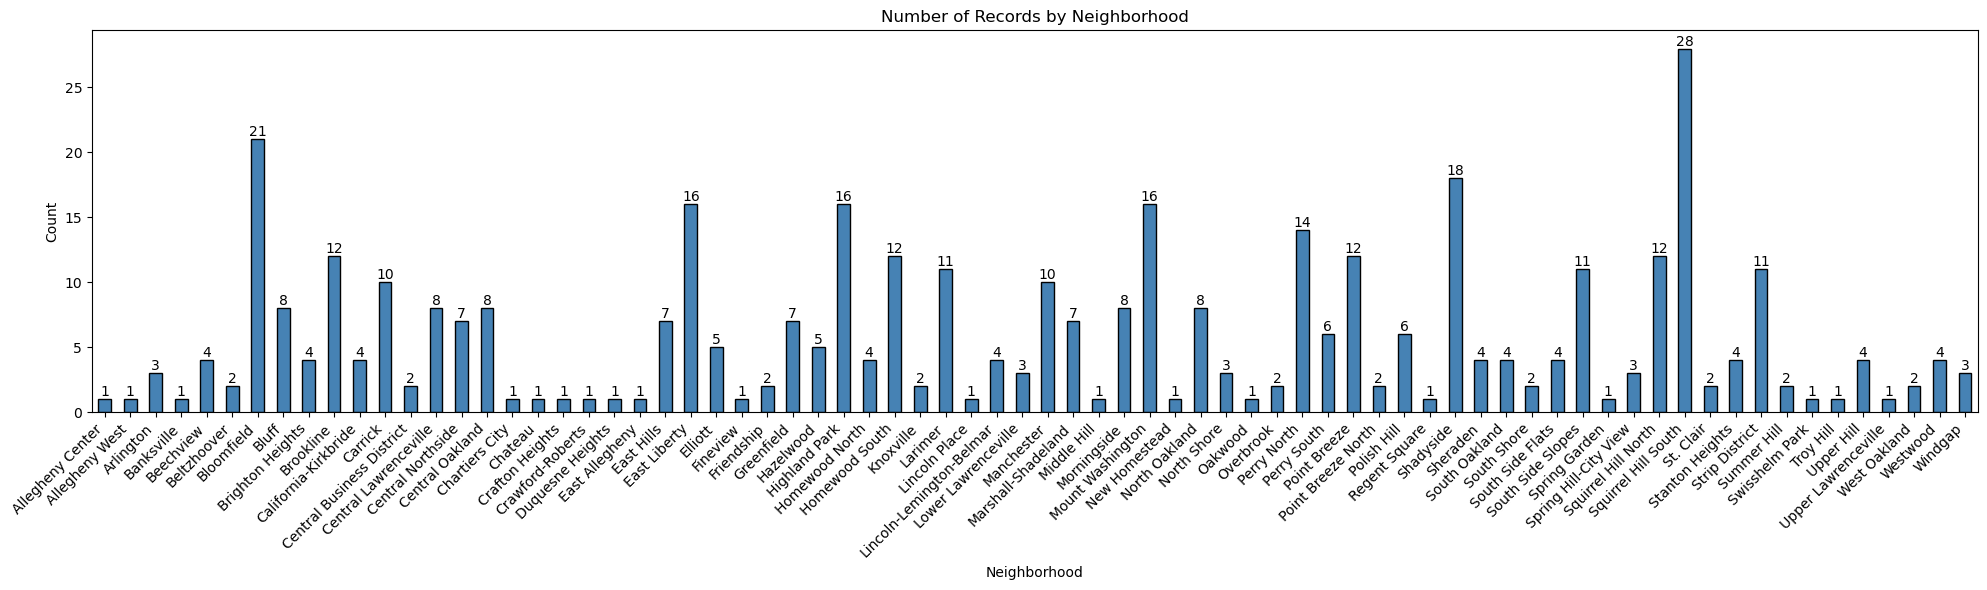

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
trafficCount = "https://data.wprdc.org/datastore/dump/6dfd4f8f-cbf5-4917-a5eb-fd07f4403167"

df = pd.read_csv(trafficCount)

counts = df["neighborhood"].value_counts().sort_index()

ax = counts.plot(kind="bar", figsize=(20, 6), color="steelblue", edgecolor="black")
ax.set_title("Number of Records by Neighborhood")
ax.set_xlabel("Neighborhood")
ax.set_ylabel("Count")

for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            int(bar.get_height()), ha="center", va="bottom")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("neighborhood_bar_graph.png", dpi=150)
plt.show()

Number of road signs 

neighborhood
South Side Flats             3672
Bloomfield                   3627
Central Business District    3491
Shadyside                    3370
Squirrel Hill South          3281
Brookline                    2256
Carrick                      2044
Central Lawrenceville        1970
Squirrel Hill North          1895
East Liberty                 1759
North Oakland                1743
Mount Washington             1630
Highland Park                1490
Beechview                    1397
Strip District               1366
Central Oakland              1327
Hazelwood                    1300
Point Breeze                 1284
Central Northside            1251
South Side Slopes            1175
East Allegheny               1066
North Shore                  1053
South Oakland                1049
Greenfield                   1048
Lower Lawrenceville          1024
Homewood South                999
Bluff                         978
Brighton Heights              903
Sheraden                      896
G

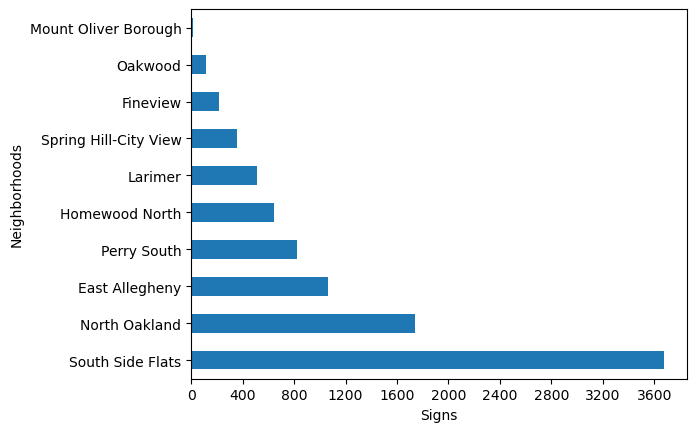

In [5]:
import pandas as pd
import numpy as np
from matplotlib.ticker import MaxNLocator

signs = pd.read_csv("0010final_signs.csv")
chart_signs = signs["neighborhood"].value_counts().iloc[::10].plot.barh(xlabel="Signs",ylabel="Neighborhoods",)
chart_signs.xaxis.set_major_locator(MaxNLocator(integer=True))

count = signs["neighborhood"].value_counts()
print(count.head(46))
print(count.tail(45))

**The Best Neighborhood**

To determine best look for overlap between top 20 car crashes and traffic violations 
All top 20 in violations have 1 record so over lap was easy to determine and is as follows  with number of road signs 

Chartiers City - 44

New Homestead - 118

Oakwood - 118

Regent square - 308

Spring garden - 239

Fineview - 217

Regent Square 9th for least crashes, 1 reported injury, most road signs from overlapping. 


**Conclusions**

Prerna- The data helped me determine that Arlington Heights could be considered the best based on the number of car crashes. However, my personal favorite neighborhood is Oakland. Even if Oakland has more car crashes than Arlington Heights, I still prefer it because of the colleges, restaurants, shops, and activities. This shows that the neighborhood with the best data results is not necessarily everyone's personal favorite. Data can help us make decisions, but personal experiences and preferences also play a role in what makes a neighborhood the best.



Ethan- There were lots of neighborhoods with counts of one, so we cannot say for sure what is the best neighborhood based on this data. However, we can see that some neighborhoods have significantly higher counts than others, which may indicate areas with more traffic or activity. I am not from around here so the only neighborhoods I have heard of are Downtown, Oakland, and Squirrel Hill. Oakland did not have many violations on record, and because I live on campus everything I need is in Oakland, so I would say it is my "favorite" neighborhood.



Amy- From the data, I can determine that if increased road signage is assumed to improve driving safety, South Side Flats should be the safest and therefore best neighborhood, while Mount Oliver Borough is the worst. When thinking about my own favorite neighborhood, however, road signage is not a big factor in my decision, especially considering that I personally do not have a car and do not drive. My personal favorite neighborhood is probably Squirrel Hill, since I enjoy walking there and have gone to the movie theater there several times. I like South Side Flats as well, the best neighborhood by signage, but mostly because my sister lives there. This demonstrates that the real “best” neighborhood to each individual is not necessarily going to be based on just one metric like we measured, but on a variety of subjective factors
